# Experiment 2: Logistic Regression After Removing Exact Duplicates

## Goal

This experiment tests whether exact duplicate rows affect Logistic Regression performance.

We will:

1. Load the original credit-card fraud dataset
2. Measure the number of duplicate rows
3. Remove exact duplicates
4. Separate features and target
5. Create a stratified train/test split
6. Scale the training features
7. Train the same Logistic Regression baseline
8. Evaluate with the same metrics used in Experiment 1

## Research Question

Does removing exact duplicate transactions change fraud-detection performance compared with the original Logistic Regression baseline?

In [1]:
import pandas as pd

data_path = "../data/raw/creditcard.csv"
df = pd.read_csv(data_path)

df.shape

(284807, 31)

In [2]:
#Checking for Duplicaet data
df.duplicated().sum()

np.int64(1081)

In [3]:
df_clean = df.drop_duplicates()

df.shape, df_clean.shape

((284807, 31), (283726, 31))

In [4]:
print("Original class counts:")
print(df["Class"].value_counts())

print("\nCleaned class counts:")
print(df_clean["Class"].value_counts())

Original class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Cleaned class counts:
Class
0    283253
1       473
Name: count, dtype: int64



### Original Dataset
Total Data = (284807, 31)

Normal = 284,315  
Fraud  = 492  

### After Removing Duplicates
Normal = 283,253  
Fraud  = 473  

### Duplicates Removed by Class
Normal = 284,315 - 283,253 = 1,062  
Fraud  = 492 - 473 = 19  

Total Duplicates Removed = 1,081  

### Final Dataset for Training
Normal = 283,253  
Fraud  = 473  

Total = 283,726


In [5]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

X.shape, y.shape

((283726, 30), (283726,))

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((226980, 30), (56746, 30), (226980,), (56746,))

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
X_train_scaled.shape, X_test_scaled.shape

((226980, 30), (56746, 30))

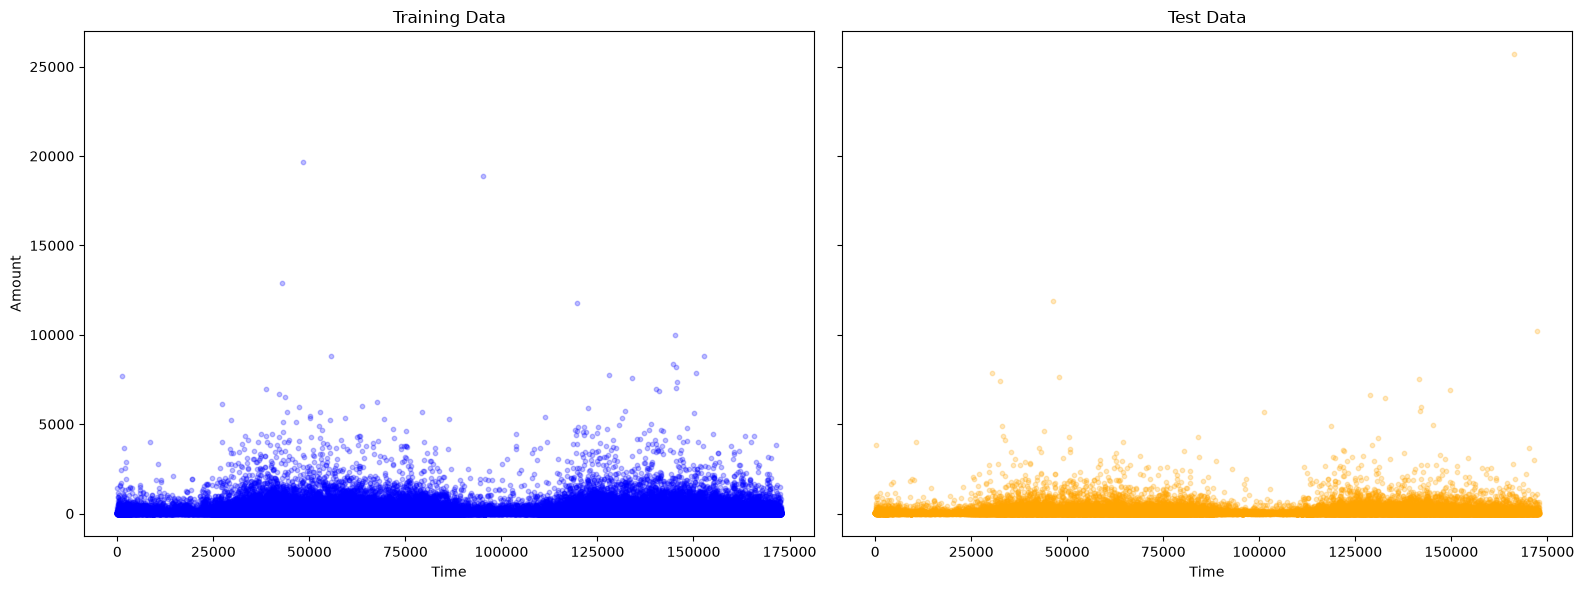

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Training data
axes[0].scatter(
    X_train["Time"],
    X_train["Amount"],
    s=10,
    alpha=0.25,
    color="blue"
)

axes[0].set_title("Training Data")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amount")


# Test data
axes[1].scatter(
    X_test["Time"],
    X_test["Amount"],
    s=10,
    alpha=0.25,
    color="orange"
)

axes[1].set_title("Test Data")
axes[1].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [12]:
# Checking Are fraud cases present in both train and test

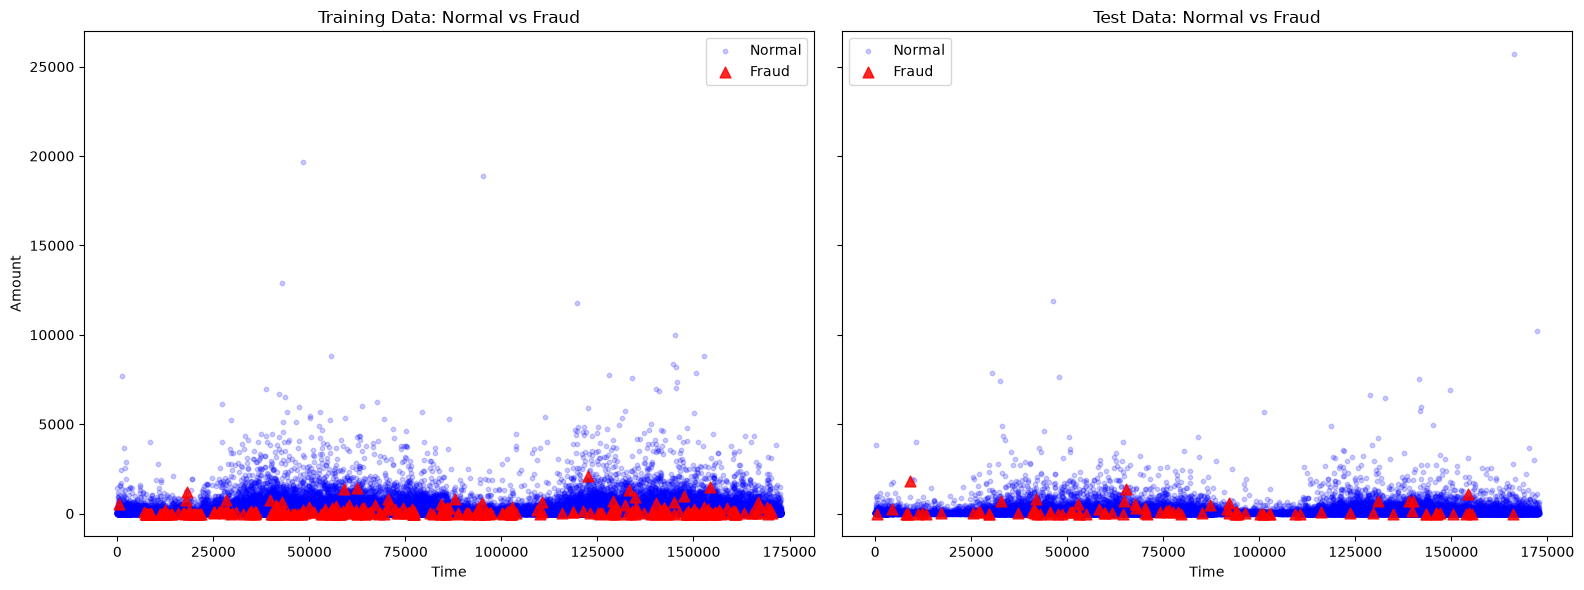

In [10]:
import matplotlib.pyplot as plt

# Training masks
train_normal = y_train == 0
train_fraud = y_train == 1

# Test masks
test_normal = y_test == 0
test_fraud = y_test == 1

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# -------------------------
# Training data
# -------------------------
axes[0].scatter(
    X_train.loc[train_normal, "Time"],
    X_train.loc[train_normal, "Amount"],
    s=10,
    alpha=0.20,
    color="blue",
    marker="o",
    label="Normal"
)

axes[0].scatter(
    X_train.loc[train_fraud, "Time"],
    X_train.loc[train_fraud, "Amount"],
    s=60,
    alpha=0.85,
    color="red",
    marker="^",
    label="Fraud"
)

axes[0].set_title("Training Data: Normal vs Fraud")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amount")
axes[0].legend()


# -------------------------
# Test data
# -------------------------
axes[1].scatter(
    X_test.loc[test_normal, "Time"],
    X_test.loc[test_normal, "Amount"],
    s=10,
    alpha=0.20,
    color="blue",
    marker="o",
    label="Normal"
)

axes[1].scatter(
    X_test.loc[test_fraud, "Time"],
    X_test.loc[test_fraud, "Amount"],
    s=60,
    alpha=0.85,
    color="red",
    marker="^",
    label="Fraud"
)

axes[1].set_title("Test Data: Normal vs Fraud")
axes[1].set_xlabel("Time")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [14]:
y_pred = model.predict(X_test_scaled)

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[56641,    10],
       [   40,    55]])


### Confusion Matrix

| Actual ↓ / Predicted → | Normal | Fraud |
|------------------------|-------:|------:|
| **Normal**             | 56,641 | 10    |
| **Fraud**              | 40     | 55    |



### Confusion Matrix Results

**TN = 56,641** → Normal correctly predicted  
**FP = 10** → Normal wrongly predicted as Fraud  
**FN = 40** → Fraud wrongly predicted as Normal  
**TP = 55** → Fraud correctly predicted


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

#precision, recall, f1

In [19]:
print("precision: ",precision)
print("recall: ", recall)
print("f1: ", f1)

precision:  0.8461538461538461
recall:  0.5789473684210527
f1:  0.6875



### Model Performance Metrics

Precision = 0.8461538461538461  
Recall = 0.5789473684210527  
F1 = 0.6875


In [22]:

print(f"precision: {precision} --> {precision:.2%}")
print(f"recall:    {recall} --> {recall:.2%}")
print(f"f1:        {f1} --> {f1:.2%}")


precision: 0.8461538461538461 --> 84.62%
recall:    0.5789473684210527 --> 57.89%
f1:        0.6875 --> 68.75%



### Model Performance Metrics

**Precision:** 0.8461538461538461 → 84.62%  
**Recall:** 0.5789473684210527 → 57.89%  
**F1 Score:** 0.6875 → 68.75%


In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

TN, FP, FN, TP = cm.ravel()

print("Normal correctly predicted (TN):", TN)
print("Normal wrongly flagged as fraud (FP):", FP)
print("Fraud missed as normal (FN):", FN)
print("Fraud correctly detected (TP):", TP)

Normal correctly predicted (TN): 56641
Normal wrongly flagged as fraud (FP): 10
Fraud missed as normal (FN): 40
Fraud correctly detected (TP): 55
